# Practice 3: Latent Space Classification

**Developed by:** Antonio Vila Leis and David Florez Mazuera

## Introduction

This project explores the use of unsupervised learning for feature extraction via an Autoencoder and subsequently leveraging those learned representations to train a classifier with limited labeled data.

The dataset used in this assignment is STL-10. It consists of 96x96 pixel color images belonging to 10 classes (such as airplanes, birds, cars, and cats). It provides a small subset of labeled images (5,000 for training, 800 per class for testing) alongside a huge pool of 100000 unlabeled images.

The project development is structured into five main phases:

1. **Setup and Preprocessing:** Loading the STL-10 dataset partitions (labeled and unlabeled) and applying appropriate preprocessing process.

2. **Baseline:** Evaluation of the performance obtained by a standard supervised CNN model (developed in Practice 1) trained solely on the labeled dataset. This establishes the benchmark to evaluate the effectiveness of the autoencoder-based approach.

3. **Unsupervised Training (Autoencoder):** Design and training of a Convolutional Autoencoder using the 100000 unlabeled images. The goal is to force the network to learn a compact and meaningful latent representation of the input space by learning to reconstruct the original images.

4. **Latent Space Classification:** Construction of a classifier on top of the frozen encoder trained in the previous step. The model will operate exclusively in the latent space, using the labeled images for training. This section also includes a thorough analysis of different regularization techniques to mitigate overfitting given the limited labeled data.

5. **Fine-Tuning:** An advanced refinement phase to explore techniques and parameters that allow for improvement of previous results.

## 1. Setup and Preprocessing

### Import Libraries and Setup

In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
    # Reduces the number of warnings
    
import tensorflow as tf
from tensorflow import keras
from keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
import random

# Configure matplotlib for inline plotting
%matplotlib inline

# Set random seeds for reproducibility
seed=123
os.environ['PYTHONHASHSEED']=str(seed)
tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

print("="*60)
print("STL-10 Dataset CNN Classifier")
print("="*60)
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print("="*60)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
# To avoid stalling due to memory problems

STL-10 Dataset CNN Classifier
TensorFlow version: 2.20.0
Keras version: 3.12.0
GPU Available: False


W0000 00:00:1779374754.560213   42982 gpu_device.cc:2342] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


### Configuration parameters

In [2]:
IMG_SIZE = 96  # STL-10 native size
UNS_BATCH_SIZE = 128
EPOCHS = 200
NUM_CLASSES = 10  # airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck
INITIAL_LR = 0.001

# Class names for visualization
CLASS_NAMES = ['airplane', 'bird', 'car', 'cat', 'deer', 
               'dog', 'horse', 'monkey', 'ship', 'truck']

print(f"Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch Size: {UNS_BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"Initial Learning Rate: {INITIAL_LR}")
print(f"\nClasses: {', '.join(CLASS_NAMES)}")

Image Size: 96x96
Batch Size: 128
Epochs: 200
Number of Classes: 10
Initial Learning Rate: 0.001

Classes: airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck


### Load STL-10 dataset

In [3]:
uns_raw, uns_info = tfds.load(
    "stl10",
    split="unlabelled",
    as_supervised=False,
    with_info=True,
    download=True
)

# Create training and validation splits from the unlabelled data
unlabelled_size = uns_info.splits['unlabelled'].num_examples
UNS_VAL_SIZE = int(unlabelled_size * 0.1)
UNS_TRAIN_SIZE = unlabelled_size - UNS_VAL_SIZE

def ae_preprocess(example):
    image = tf.cast(example["image"], tf.float32) / 255.0
    return image, image

uns_processed = (
    uns_raw
    .map(ae_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .ignore_errors()
    .cache()
)

uns_val = (
    uns_processed
    .take(UNS_VAL_SIZE)
    .batch(UNS_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

uns_train = (
    uns_processed
    .skip(UNS_VAL_SIZE)
    .shuffle(1000, seed=seed)
    .batch(UNS_BATCH_SIZE)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)

**Important:** When loading the models, using ``.repeat()`` helps prevent errors caused by corrupted samples. You must then specify the ``steps_per_epoch`` argument during training as shown below.

````
steps_per_epoch = unlabelled_size // BATCH_SIZE
autoencoder.fit(
    ds_unlabeled,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=None
)


In [4]:
ds_train_raw = tfds.load('stl10', split='train[:80%]', as_supervised=True)
ds_val_raw   = tfds.load('stl10', split='train[80%:]', as_supervised=True)
ds_test_raw  = tfds.load('stl10', split='test', as_supervised=True)

In [5]:
import matplotlib.pyplot as plt

def plot(history, only_loss=False):
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(loss) + 1)

    if not only_loss:
        accuracy = history.history["accuracy"]
        val_accuracy = history.history["val_accuracy"]

        plt.figure(figsize=(8, 5))
        plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
        plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
        plt.title("Training and validation accuracy")
        plt.xlabel("Epochs")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.show()
        
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

In [6]:
def reset_seeds():
    os.environ['PYTHONHASHSEED'] = str(seed)
    tf.random.set_seed(seed)
    np.random.seed(seed)
    random.seed(seed)

In [7]:
builder = tfds.builder('stl10')
info = builder.info
print(info.features)
print(info.splits)

FeaturesDict({
    'image': Image(shape=(96, 96, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
})
{'train': <SplitInfo num_examples=5000, num_shards=1>, 'test': <SplitInfo num_examples=8000, num_shards=2>, 'unlabelled': <SplitInfo num_examples=100000, num_shards=16>}


### Preprocessing

A preprocessing pipeline has been applied with the following key steps:

* Label transformation (One-Hot Encoding and Normalization): Numerical labels are converted into a categorical format and normalized (TODO ver si encaja poner normalized aqui con la explicacion posterior). This way, the model is prevented from mistakenly assuming that a hierarchical order exists among the classes.

* Batching: Finally, the data is packed into groups of 32 elements. This optimizes resource consumption during training.

In [ ]:
def one_hot_encoding(image, label):
    label = tf.one_hot(label, depth=10)
    return image, label

# def prepare_labeled_data(image, label):
#     image = tf.cast(image, tf.float32) / 255.0 
#     label = tf.cast(label, tf.int32)
#     label = tf.one_hot(label, depth=10)
#     return image, label


ds_train = ds_train_raw.map(one_hot_encoding).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_val = ds_val_raw.map(one_hot_encoding).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_test = ds_test_raw.map(one_hot_encoding).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)

Shape images: (32, 96, 96, 3)
Shape labels: (32, 10)
Min/Max images: tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(1.0, shape=(), dtype=float32)
Sample label: tf.Tensor([0. 1. 0. 0. 0. 0. 0. 0. 0. 0.], shape=(10,), dtype=float32)


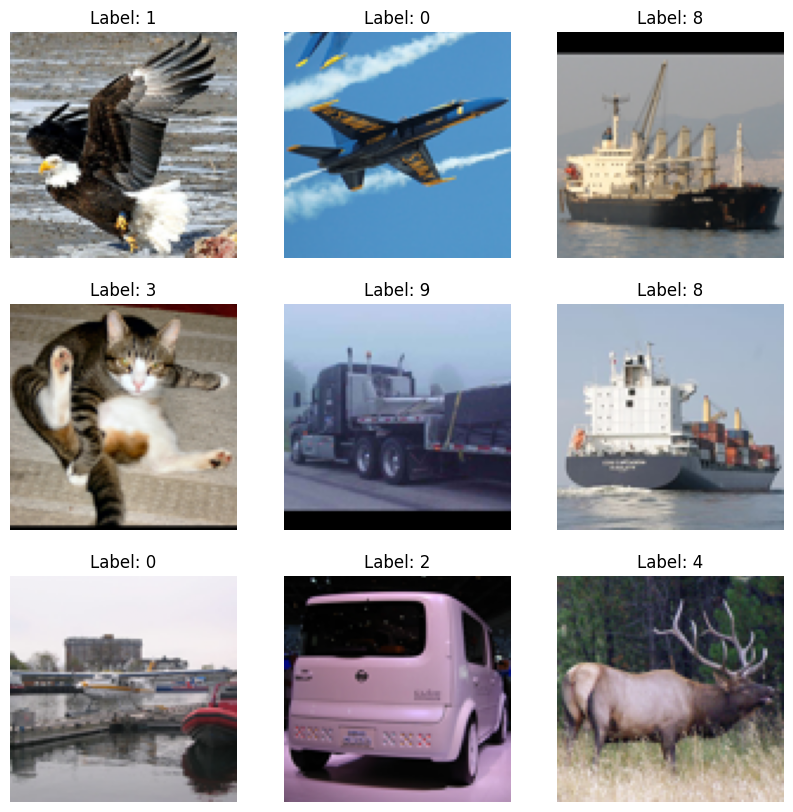

In [9]:
# Verify that the data is correct
import matplotlib.pyplot as plt

for images, labels in ds_train.take(1):
    print("Shape images:", images.shape)
    print("Shape labels:", labels.shape)
    print("Min/Max images:", tf.reduce_min(images), tf.reduce_max(images))
    print("Sample label:", labels[0])

# Visualize some images and their labels
for images, labels in ds_train.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f"Label: {tf.argmax(labels[i])}")
        plt.axis('off')
    plt.show()

## 2. Baseline

In [10]:
def residual_block(x, filters, kernel_size=3, stride=1):
    shortcut = x

    # First layer of the block
    x = layers.SeparableConv2D(filters, kernel_size, strides=stride, padding='same')(x)
    x = layers.Activation('relu')(x)

    # Second layer of the block
    x = layers.SeparableConv2D(filters, kernel_size, padding='same')(x)

    # If shapes don't match (e.g., due to stride), adjust the shortcut
    if stride > 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1, 1), strides=stride, padding='same')(shortcut)

    x = layers.Add()([x, shortcut]) # The Residual Connection
    x = layers.Activation('relu')(x)
    return x

inputs = keras.Input(shape=(96, 96, 3))

# Data Augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1, fill_mode='reflect')(x)
x = layers.RandomZoom(0.1, fill_mode='reflect')(x)

# Entry Flow
x = layers.SeparableConv2D(32, (3, 3), padding='same')(x)
x = layers.Activation('relu')(x)

# Residual Stages (Increasing Depth)
x = residual_block(x, 64, stride=2)
x = residual_block(x, 64)

x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

x = residual_block(x, 256, stride=2)
x = residual_block(x, 256)

x = residual_block(x, 512, stride=2)
x = residual_block(x, 512)

# Classifier Head
x = layers.GlobalAveragePooling2D()(x) # Better than Flatten for deep nets
x = layers.Dropout(0.5)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_tuned = keras.Model(inputs=inputs, outputs=outputs)

model_tuned.compile(optimizer='adam',
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])

model_tuned.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip         │ (None, 96, 96, 3) │          0 │ input_layer[0][0] │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 96, 96, 3) │          0 │ random_flip[0][0] │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom         │ (None, 96, 96, 3) │          0 │ random_rotation[… │
│ (RandomZoom)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d    │ (None, 96, 96,    │        155 │ random_zoom[0][0] │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 96, 96,    │          0 │ separable_conv2d… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_1  │ (None, 48, 48,    │      2,400 │ activation[0][0]  │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_2  │ (None, 48, 48,    │      4,736 │ activation_1[0][… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 48, 48,    │      2,112 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 48, 48,    │          0 │ separable_conv2d… │
│                     │ 64)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 48, 48,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_3  │ (None, 48, 48,    │      4,736 │ activation_2[0][… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_4  │ (None, 48, 48,    │      4,736 │ activation_3[0][… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 48, 48,    │          0 │ separable_conv2d… │
│                     │ 64)               │            │ activation_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 48, 48,    │          0 │ add_1[0][0]     

 Total params: 1,561,733 (5.96 MB)

 Trainable params: 1,561,733 (5.96 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history_tuned = model_tuned.fit(ds_train, validation_data=ds_val,
                    epochs=100, callbacks=[early_stopping, reduce_lr])

model_tuned.save("experiments/baseline.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 18s 119ms/step - accuracy: 0.1390 - loss: 2.2419 - val_accuracy: 0.1890 - val_loss: 2.1414 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 112ms/step - accuracy: 0.2085 - loss: 2.0576 - val_accuracy: 0.2220 - val_loss: 2.0002 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 124ms/step - accuracy: 0.2450 - loss: 1.9190 - val_accuracy: 0.2580 - val_loss: 1.8821 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 118ms/step - accuracy: 0.2718 - loss: 1.8562 - val_accuracy: 0.2690 - val_loss: 1.8298 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.2815 - loss: 1.8063 - val_accuracy: 0.2800 - val_loss: 1.8003 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 116ms/step - accuracy: 0.2988 - loss: 1.7734 - val_accuracy: 0.2850 - val_loss: 1.7840 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 115ms/step - accura

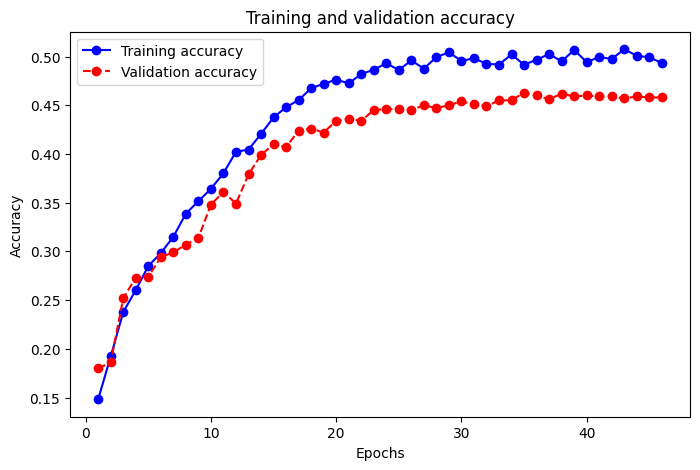

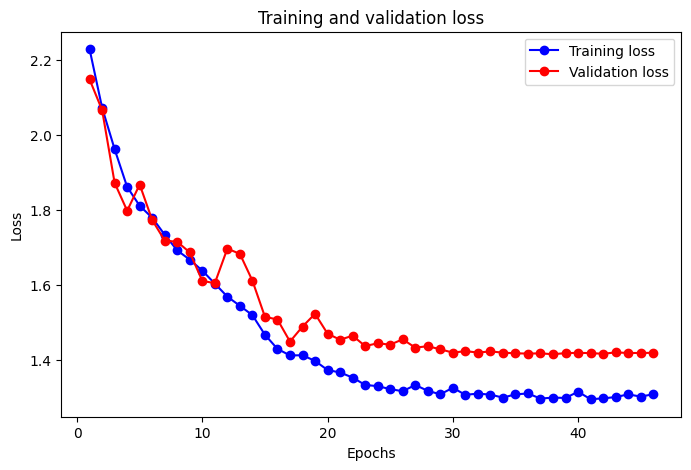

In [ ]:
plot(history_tuned)

In [12]:
print("\n--- Test Evaluation ---")
test_loss, test_acc = model_tuned.evaluate(ds_test)
print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")


--- Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.5441 - loss: 1.2384
Test Accuracy: 0.5441 | Test Loss: 1.2384


## 3. Unsupervised Training (Autoencoder)

In [9]:
LATENT_DIM = 1024
encoder_input = layers.Input(shape=(96, 96, 3), name='encoder_input')
e1 = layers.Conv2D(32, 3, activation='relu', padding='same', strides=2, name='e1')(encoder_input)
e2 = layers.Conv2D(64, 3, activation='relu', padding='same', strides=2, name='e2')(e1)
e3 = layers.Conv2D(128, 3, activation='relu', padding='same', strides=2, name='e3')(e2)
e4 = layers.Conv2D(256, 3, activation='relu', padding='same', strides=2, name='e4')(e3)
latent = layers.Flatten(name='flatten')(e4)
latent = layers.Dense(LATENT_DIM, activation='relu', name='latent')(latent)
d = layers.Dense(6 * 6 * 256, activation='relu', name='d_dense')(latent)
d = layers.Reshape((6, 6, 256), name='d_reshape')(d)
d = layers.Conv2DTranspose(128, 3, activation='relu', padding='same', strides=2, name='d_conv1')(d)
d = layers.Concatenate(name='skip1')([d, e3])
d = layers.Conv2DTranspose(64, 3, activation='relu', padding='same', strides=2, name='d_conv2')(d)
d = layers.Concatenate(name='skip2')([d, e2])
d = layers.Conv2DTranspose(32, 3, activation='relu', padding='same', strides=2, name='d_conv3')(d)
d = layers.Concatenate(name='skip3')([d, e1])
decoder_output = layers.Conv2DTranspose(3, 3, activation='sigmoid', padding='same', strides=2, name='decoder_output')(d)
autoencoder = models.Model(encoder_input, decoder_output, name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e1 (Conv2D)         │ (None, 48, 48,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e2 (Conv2D)         │ (None, 24, 24,    │     18,496 │ e1[0][0]          │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e3 (Conv2D)         │ (None, 12, 12,    │     73,856 │ e2[0][0]          │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e4 (Conv2D)         │ (None, 6, 6, 256) │    295,168 │ e3[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 9216)      │          0 │ e4[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent (Dense)      │ (None, 1024)      │  9,438,208 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_dense (Dense)     │ (None, 9216)      │  9,446,400 │ latent[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_reshape (Reshape) │ (None, 6, 6, 256) │          0 │ d_dense[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv1             │ (None, 12, 12,    │    295,040 │ d_reshape[0][0]   │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip1 (Concatenate) │ (None, 12, 12,    │          0 │ d_conv1[0][0],    │
│                     │ 256)              │            │ e3[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv2             │ (None, 24, 24,    │    147,520 │ skip1[0][0]       │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip2 (Concatenate) │ (None, 24, 24,    │          0 │ d_conv2[0][0],    │
│                     │ 128)              │            │ e2[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv3             │ (None, 48, 48,    │     36,896 │ skip2[0][0]       │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip3 (Concatenate) │ (None, 48, 48,    │          0 │ d_conv3[0][0],    │
│                     │ 64)               │            │ e1[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, 96, 96, 3) │      1,731 │ skip3[0][0]       │
│ (Conv2DTranspose)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,754,211 (75.36 MB)

 Trainable params: 19,754,211 (75.36 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
import keras
from tensorflow import expand_dims

steps_per_epoch = UNS_TRAIN_SIZE // UNS_BATCH_SIZE

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)

history_uns = autoencoder.fit(
    uns_train, 
    epochs=100, 
    steps_per_epoch=steps_per_epoch,
    validation_data=uns_val,
    callbacks=[early_stopping]
)

autoencoder.save("experiments/basic_autoencoder.keras")


Epoch 1/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 182s 253ms/step - loss: 0.0070 - val_loss: 0.0015
Epoch 2/100


/Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Universidad/MIA/DL/dl_p3/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


703/703 ━━━━━━━━━━━━━━━━━━━━ 199s 281ms/step - loss: 0.0011 - val_loss: 9.2592e-04
Epoch 3/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 176s 250ms/step - loss: 7.4404e-04 - val_loss: 5.9170e-04
Epoch 4/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 161s 229ms/step - loss: 5.7567e-04 - val_loss: 4.8330e-04
Epoch 5/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 159s 226ms/step - loss: 4.8574e-04 - val_loss: 4.1451e-04
Epoch 6/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 156s 221ms/step - loss: 4.1633e-04 - val_loss: 3.6527e-04
Epoch 7/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 159s 226ms/step - loss: 3.7727e-04 - val_loss: 3.7767e-04
Epoch 8/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 159s 226ms/step - loss: 3.3361e-04 - val_loss: 3.0597e-04
Epoch 9/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 177s 251ms/step - loss: 3.2068e-04 - val_loss: 3.0890e-04
Epoch 10/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 174s 247ms/step - loss: 2.9066e-04 - val_loss: 2.5718e-04
Epoch 11/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 175s 248ms/step - loss: 2.7664e-04 - val_loss: 2.8709e-04
Epoch 12/100
703/703 ━━━

/Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Universidad/MIA/DL/dl_p3/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


703/703 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 1.1494e-04 - val_loss: 1.1202e-04
Epoch 39/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 147s 208ms/step - loss: 1.1710e-04 - val_loss: 1.5278e-04
Epoch 40/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 149s 210ms/step - loss: 1.1900e-04 - val_loss: 1.0667e-04
Epoch 41/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 146s 207ms/step - loss: 1.1370e-04 - val_loss: 1.2368e-04
Epoch 42/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 149s 211ms/step - loss: 1.1196e-04 - val_loss: 1.1225e-04
Epoch 43/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 148s 210ms/step - loss: 1.0902e-04 - val_loss: 1.1298e-04
Epoch 44/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 157s 224ms/step - loss: 1.0714e-04 - val_loss: 1.0196e-04
Epoch 45/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 158s 224ms/step - loss: 1.0690e-04 - val_loss: 1.0754e-04
Epoch 46/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 158s 224ms/step - loss: 1.0391e-04 - val_loss: 9.6315e-05
Epoch 47/100
703/703 ━━━━━━━━━━━━━━━━━━━━ 206s 293ms/step - loss: 1.0385e-04 - val_loss: 1.2128e-04
Epoch 48/100
703/

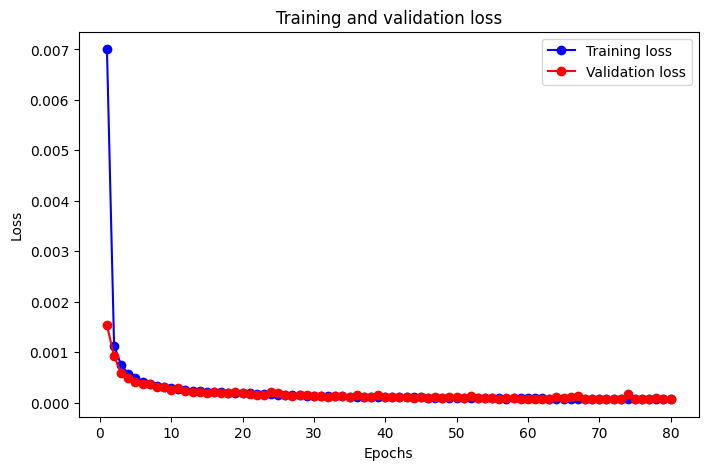

In [11]:
plot(history_uns, only_loss=True)

## 3.1 Verificacion de Reconstrucciones


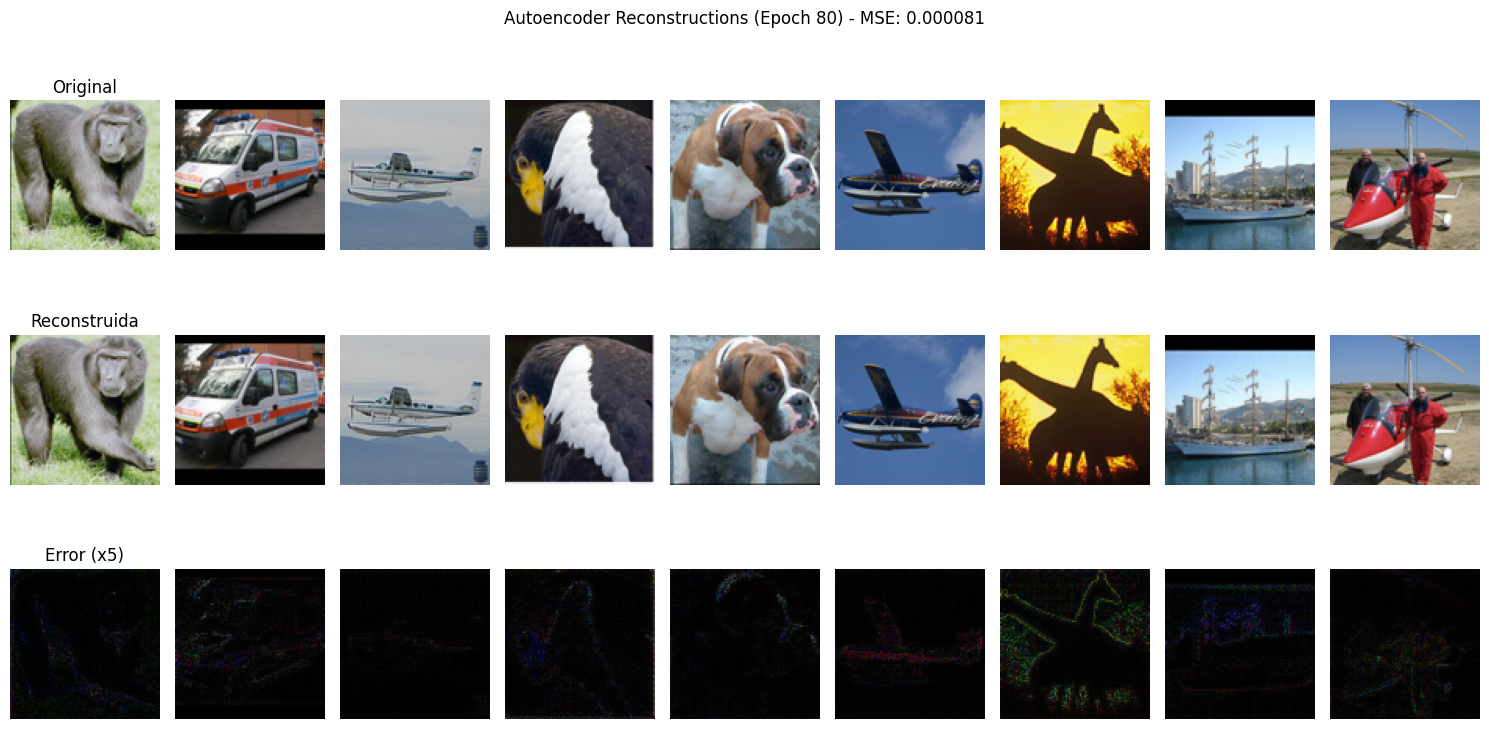

MSE por imagen - min: 0.000011, max: 0.000194, mean: 0.000071


In [12]:
import numpy as np

# Reconstruir imagenes del validation set
n_samples = 9
for images, _ in uns_val.take(1):
    originals = images[:n_samples].numpy()
    reconstructions = autoencoder.predict(originals, verbose=0)
    
    fig, axes = plt.subplots(3, n_samples, figsize=(15, 8))
    for i in range(n_samples):
        axes[0, i].imshow(originals[i])
        axes[0, i].set_title("Original" if i == 0 else "")
        axes[0, i].axis("off")
        
        axes[1, i].imshow(reconstructions[i])
        axes[1, i].set_title("Reconstruida" if i == 0 else "")
        axes[1, i].axis("off")
        
        diff = np.abs(originals[i] - reconstructions[i])
        axes[2, i].imshow(diff * 5)
        axes[2, i].set_title("Error (x5)" if i == 0 else "")
        axes[2, i].axis("off")
    
    plt.suptitle(f"Autoencoder Reconstructions (Epoch {len(history_uns.history['loss'])}) - MSE: {history_uns.history['val_loss'][-1]:.6f}")
    plt.tight_layout()
    plt.show()
    
    mse_per_image = np.mean((originals - reconstructions) ** 2, axis=(1, 2, 3))
    print(f"MSE por imagen - min: {mse_per_image.min():.6f}, max: {mse_per_image.max():.6f}, mean: {mse_per_image.mean():.6f}")
    break


## 4. Latent Space Classification

### 4.1 Approach 1: Using Decoder's Latent Output

In [ ]:
import keras
from keras import layers, models

# Get the pretrained encoder - SIMPLER
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")
encoder_input = autoencoder.input   # input del modelo completo
latent_output = autoencoder.get_layer('latent').output
pretrained_encoder = models.Model(inputs=encoder_input, outputs=latent_output)
pretrained_encoder.trainable = False

# Build the new classifier
inputs = layers.Input(shape=(96, 96, 3))
x = pretrained_encoder(inputs)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier = models.Model(inputs=inputs, outputs=outputs, name="latent_classifier")

classifier.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier.summary()

Model: "latent_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_14 (Functional)      │ (None, 1024)           │     9,826,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_38 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_39 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,123,210 (38.62 MB)

 Trainable params: 296,586 (1.13 MB)

 Non-trainable params: 9,826,624 (37.49 MB)

In [60]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history_classifier = classifier.fit(ds_train, validation_data=ds_val,
                    epochs=100, callbacks=[early_stopping, reduce_lr])

classifier.save("experiments/latent_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.2740 - loss: 2.1055 - val_accuracy: 0.3230 - val_loss: 1.7764 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3458 - loss: 1.7648 - val_accuracy: 0.3520 - val_loss: 1.7339 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3598 - loss: 1.6978 - val_accuracy: 0.3430 - val_loss: 1.7139 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3823 - loss: 1.6498 - val_accuracy: 0.3430 - val_loss: 1.7049 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4025 - loss: 1.6003 - val_accuracy: 0.3720 - val_loss: 1.6928 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4200 - loss: 1.5612 - val_accuracy: 0.3750 - val_loss: 1.6708 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4423 - loss: 1

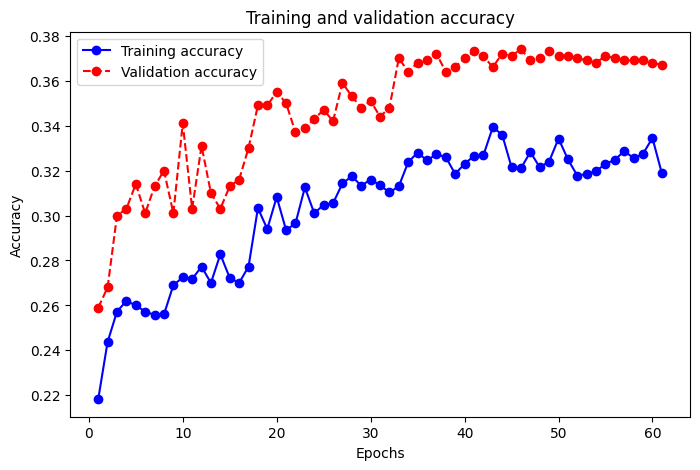

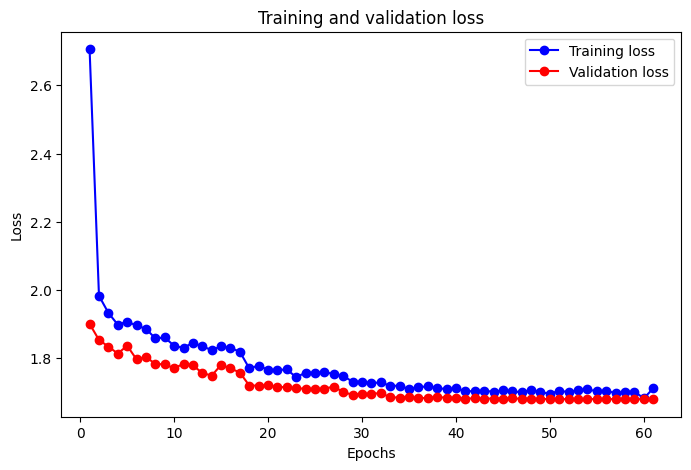

In [16]:
plot(history_classifier)

In [17]:
print("\n--- Test Evaluation ---")
test_loss, test_acc = classifier.evaluate(ds_test)
print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")


--- Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.3647 - loss: 1.6712
Test Accuracy: 0.3647 | Test Loss: 1.6712


## 4.2 Approach 2: Using Intermediate Feature Maps

In [18]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))
x = feature_extractor(inputs)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e4 = models.Model(inputs=inputs, outputs=outputs, name="e4_feature_classifier")

classifier_e4.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e4.summary()

Model: "e4_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_3 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [19]:
# Train the e4-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e4 = classifier_e4.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e4.save("experiments/e4_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.2087 - loss: 2.4206 - val_accuracy: 0.2290 - val_loss: 2.1108 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2505 - loss: 2.1230 - val_accuracy: 0.2440 - val_loss: 1.9626 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2690 - loss: 2.0243 - val_accuracy: 0.2760 - val_loss: 1.9370 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2825 - loss: 1.9305 - val_accuracy: 0.3160 - val_loss: 1.8527 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2965 - loss: 1.8916 - val_accuracy: 0.2610 - val_loss: 2.0113 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3052 - loss: 1.8401 - val_accuracy: 0.3160 - val_loss: 1.8179 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3063 - loss: 1.

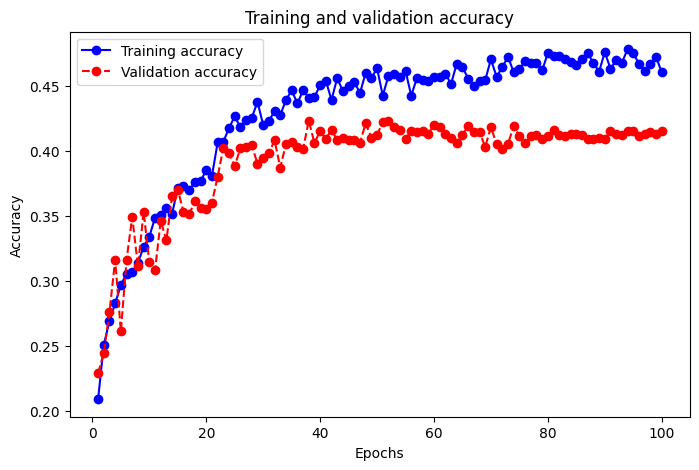

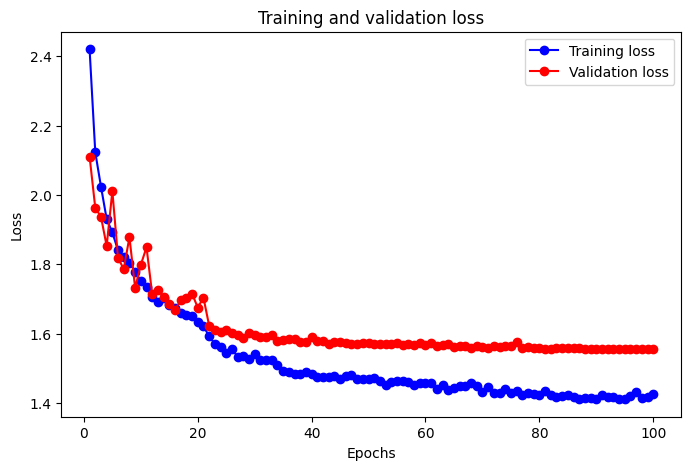

In [20]:
plot(history_e4)

In [21]:
print("\n--- E4 Classifier Test Evaluation ---")
test_loss_e4, test_acc_e4 = classifier_e4.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e4:.4f} | Test Loss: {test_loss_e4:.4f}")


--- E4 Classifier Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4335 - loss: 1.5213
Test Accuracy: 0.4335 | Test Loss: 1.5213


### 4.3 Approach 3: Data augmentation

In [22]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))

x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1, fill_mode='reflect')(x)
x = layers.RandomZoom(0.1, fill_mode='reflect')(x)

x = feature_extractor(x)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e5 = models.Model(inputs=inputs, outputs=outputs, name="e5_feature_classifier")

classifier_e5.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e5.summary()

Model: "e5_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_4 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [23]:
# Train the e5-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e5 = classifier_e5.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e5.save("experiments/e5_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.2235 - loss: 2.3886 - val_accuracy: 0.2050 - val_loss: 2.1734 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2465 - loss: 2.1551 - val_accuracy: 0.2600 - val_loss: 1.9914 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2623 - loss: 2.0328 - val_accuracy: 0.2590 - val_loss: 1.9263 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2695 - loss: 1.9793 - val_accuracy: 0.2940 - val_loss: 1.8741 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.2835 - loss: 1.9237 - val_accuracy: 0.3090 - val_loss: 1.8781 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2895 - loss: 1.8932 - val_accuracy: 0.2970 - val_loss: 1.8980 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3050 - loss

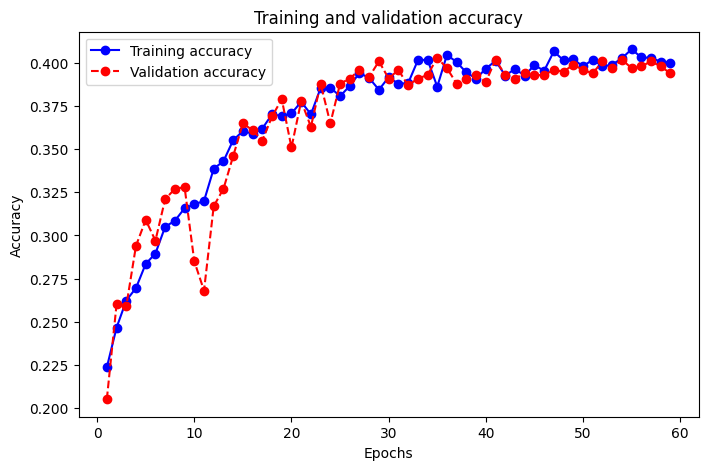

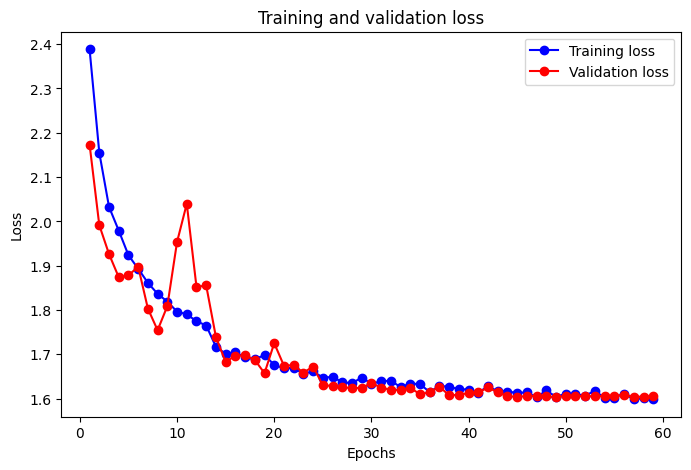

In [24]:
plot(history_e5)

In [25]:
print("\n--- E5 Classifier Test Evaluation ---")
test_loss_e5, test_acc_e5 = classifier_e5.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e5:.4f} | Test Loss: {test_loss_e5:.4f}")


--- E5 Classifier Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4031 - loss: 1.5861
Test Accuracy: 0.4031 | Test Loss: 1.5861


## 4.4 Approach 4: Using L1

In [26]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))
x = feature_extractor(inputs)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l1(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l1(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e6 = models.Model(inputs=inputs, outputs=outputs, name="e6_feature_classifier")

classifier_e6.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e6.summary()

Model: "e6_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_5 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [27]:
# Train the e6-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e6 = classifier_e6.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e6.save("experiments/e6_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.2183 - loss: 2.8705 - val_accuracy: 0.2330 - val_loss: 2.5427 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2573 - loss: 2.5302 - val_accuracy: 0.2690 - val_loss: 2.4084 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2705 - loss: 2.4139 - val_accuracy: 0.2560 - val_loss: 2.4205 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2767 - loss: 2.3382 - val_accuracy: 0.2820 - val_loss: 2.3352 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2970 - loss: 2.2580 - val_accuracy: 0.3040 - val_loss: 2.1972 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2975 - loss: 2.2211 - val_accuracy: 0.2720 - val_loss: 2.3820 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3150 - loss: 2.

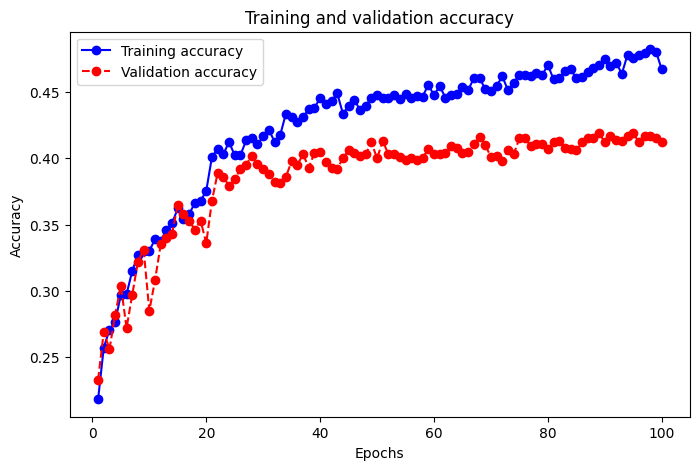

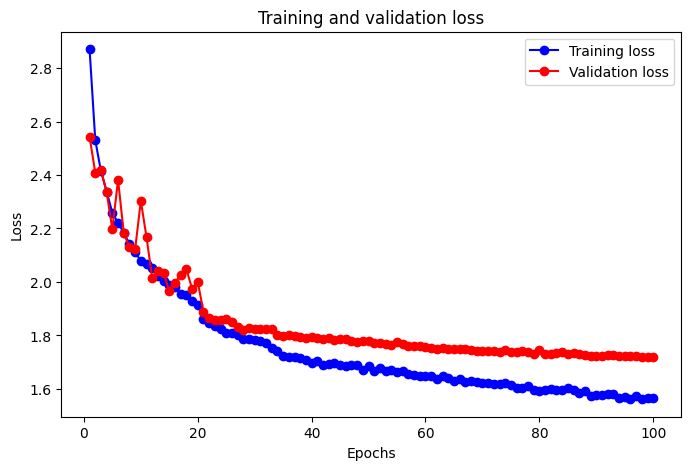

In [28]:
plot(history_e6)

In [29]:
print("\n--- E6 Classifier Test Evaluation ---")
test_loss_e6, test_acc_e6 = classifier_e6.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e6:.4f} | Test Loss: {test_loss_e6:.4f}")


--- E6 Classifier Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4374 - loss: 1.6803
Test Accuracy: 0.4374 | Test Loss: 1.6803


## 4.5 Approach 5: Using L2

In [30]:
import keras
from keras import layers, models

# Get the pretrained autoencoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

# Extract intermediate layer e4 (before flatten and dense bottleneck)
# e4 output shape: (None, 6, 6, 256)
encoder_input = autoencoder.input
e4_output = autoencoder.get_layer('e4').output

# Create feature extractor model (encoder up to e4)
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
feature_extractor.trainable = False

# Build classifier using intermediate features
inputs = layers.Input(shape=(96, 96, 3))
x = feature_extractor(inputs)  # (None, 6, 6, 256) = 9216 features
x = layers.GlobalAveragePooling2D()(x)  # → (256,)
x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_e7 = models.Model(inputs=inputs, outputs=outputs, name="e7_feature_classifier")

classifier_e7.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_e7.summary()

Model: "e7_feature_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_6 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 100,746 (393.54 KB)

 Non-trainable params: 389,184 (1.48 MB)

In [31]:
# Train the e7-based classifier
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=5, min_lr=1e-7, verbose=1)

history_e7 = classifier_e7.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[early_stopping, reduce_lr]
)

classifier_e7.save("experiments/e7_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.2288 - loss: 2.4033 - val_accuracy: 0.2140 - val_loss: 2.2132 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2515 - loss: 2.1582 - val_accuracy: 0.2730 - val_loss: 1.9475 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2765 - loss: 2.0312 - val_accuracy: 0.3090 - val_loss: 1.8641 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2867 - loss: 1.9741 - val_accuracy: 0.2890 - val_loss: 1.8950 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2957 - loss: 1.9212 - val_accuracy: 0.3270 - val_loss: 1.8262 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3027 - loss: 1.8763 - val_accuracy: 0.3310 - val_loss: 1.7867 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3092 - loss: 1.

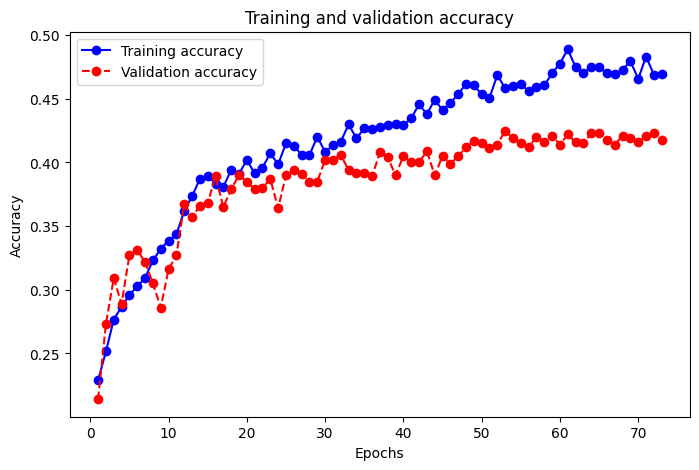

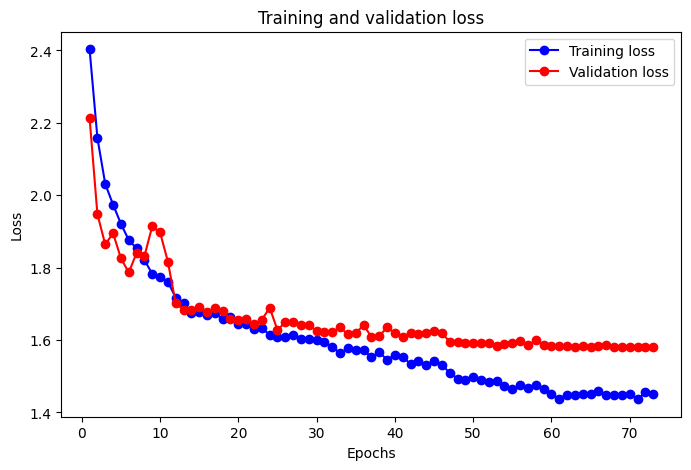

In [32]:
plot(history_e7)

In [33]:
print("\n--- E7 Classifier Test Evaluation ---")
test_loss_e7, test_acc_e7 = classifier_e7.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_e7:.4f} | Test Loss: {test_loss_e7:.4f}")


--- E7 Classifier Test Evaluation ---
  1/250 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.3750 - loss: 1.6406

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4329 - loss: 1.5493
Test Accuracy: 0.4329 | Test Loss: 1.5493


## 5. Fine-Tuning

In [34]:
import keras
from keras import layers, models
from keras.callbacks import ReduceLROnPlateau, EarlyStopping
import numpy as np

def build_classifier_with_trainable_encoder(autoencoder, trainable_layers, name_suffix):
    encoder_input = autoencoder.input
    e4_output = autoencoder.get_layer('e4').output
    feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
    
    for layer in feature_extractor.layers:
        layer.trainable = layer.name in trainable_layers
    
    inputs = layers.Input(shape=(96, 96, 3))
    x = feature_extractor(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation='softmax')(x)
    classifier = models.Model(inputs=inputs, outputs=outputs, name=f"finetune_{name_suffix}")
    
    return classifier, feature_extractor

def count_trainable_params(model):
    trainable = sum([w.numpy().size for w in model.trainable_weights])
    non_trainable = sum([w.numpy().size for w in model.non_trainable_weights])
    return trainable, non_trainable

## Experiment 1: Partial Fine-tuning (Last Block - e4 only)

In [35]:
# Experiment 1: Unfreeze only the last encoder block (e4)
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

classifier_exp1, fexp1 = build_classifier_with_trainable_encoder(
    autoencoder, 
    trainable_layers=['e4'],
    name_suffix='e4_only'
)

trainable, non_trainable = count_trainable_params(classifier_exp1)
print(f"\nTrainable params: {trainable:,} ({trainable/1e6:.2f}M)")
print(f"Non-trainable params: {non_trainable:,} ({non_trainable/1e6:.2f}M)")
print(f"Trainable layers: e4 (last encoder block)")

classifier_exp1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_exp1.summary()


Trainable params: 395,914 (0.40M)
Non-trainable params: 94,016 (0.09M)
Trainable layers: e4 (last encoder block)


Model: "finetune_e4_only"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_7 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 395,914 (1.51 MB)

 Non-trainable params: 94,016 (367.25 KB)

In [36]:
# Train Experiment 1
reduce_lr_exp1 = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop_exp1 = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training Experiment 1: Fine-tuning e4 only...")
history_exp1 = classifier_exp1.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp1, early_stop_exp1],
    verbose=1
)

print(f"Best val accuracy: {max(history_exp1.history['val_accuracy']):.4f}")

print(f"Total epochs trained: {len(history_exp1.history['loss'])}")

Training Experiment 1: Fine-tuning e4 only...
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.1725 - loss: 2.7225 - val_accuracy: 0.1990 - val_loss: 2.1439 - learning_rate: 1.0000e-04
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2240 - loss: 2.4266 - val_accuracy: 0.2620 - val_loss: 1.9801 - learning_rate: 1.0000e-04
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2387 - loss: 2.3250 - val_accuracy: 0.2870 - val_loss: 1.9841 - learning_rate: 1.0000e-04
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2453 - loss: 2.2442 - val_accuracy: 0.2450 - val_loss: 1.9806 - learning_rate: 1.0000e-04
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2508 - loss: 2.1799 - val_accuracy: 0.2580 - val_loss: 2.0554 - learning_rate: 1.0000e-04
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2587 - loss: 2.1331 - val_accuracy: 0.3240 - val_loss: 1.8101 - learning_rate: 1.0000e-04
Epoch 7/100


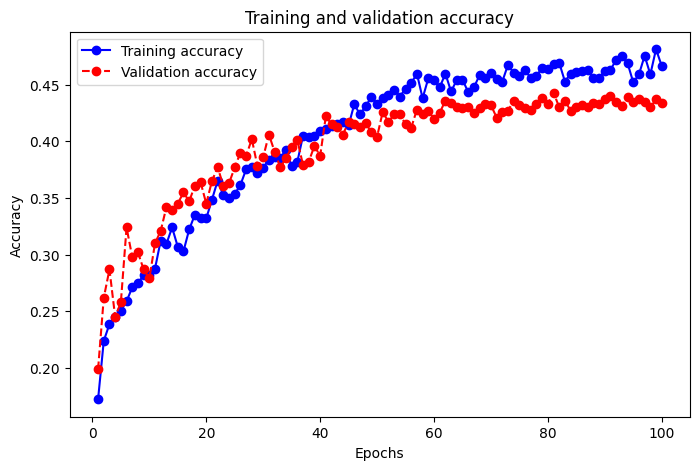

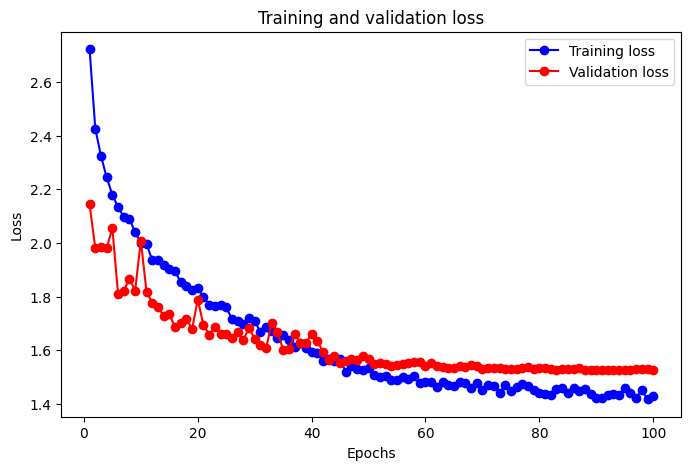

In [37]:
# Plot Experiment 1 learning curves
plot(history_exp1)

In [38]:
classifier_exp1.save("experiments/finetune_e4_only.keras")

## Experiment 2: Partial Fine-tuning (Last 2 Blocks - e3 + e4)

In [39]:
# Experiment 2: Unfreeze last 2 encoder blocks (e3 + e4)
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

classifier_exp2, fexp2 = build_classifier_with_trainable_encoder(
    autoencoder, 
    trainable_layers=['e3', 'e4'],
    name_suffix='e3_e4'
)

trainable, non_trainable = count_trainable_params(classifier_exp2)
print(f"\nTrainable params: {trainable:,} ({trainable/1e6:.2f}M)")
print(f"Non-trainable params: {non_trainable:,} ({non_trainable/1e6:.2f}M)")
print(f"Trainable layers: e3, e4 (last 2 encoder blocks)")

classifier_exp2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_exp2.summary()


Trainable params: 469,770 (0.47M)
Non-trainable params: 20,160 (0.02M)
Trainable layers: e3, e4 (last 2 encoder blocks)


Model: "finetune_e3_e4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_8 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 469,770 (1.79 MB)

 Non-trainable params: 20,160 (78.75 KB)

In [40]:
# Train Experiment 2
reduce_lr_exp2 = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop_exp2 = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training Experiment 2: Fine-tuning e3 + e4...")
history_exp2 = classifier_exp2.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp2, early_stop_exp2],
    verbose=1
)

print(f"Best val accuracy: {max(history_exp2.history['val_accuracy']):.4f}")

print(f"Total epochs trained: {len(history_exp2.history['loss'])}")

Training Experiment 2: Fine-tuning e3 + e4...
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.1698 - loss: 2.7116 - val_accuracy: 0.2140 - val_loss: 2.1813 - learning_rate: 1.0000e-04
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.2175 - loss: 2.4166 - val_accuracy: 0.2480 - val_loss: 2.1072 - learning_rate: 1.0000e-04
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2230 - loss: 2.3215 - val_accuracy: 0.2560 - val_loss: 2.0804 - learning_rate: 1.0000e-04
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2522 - loss: 2.2366 - val_accuracy: 0.2770 - val_loss: 1.9917 - learning_rate: 1.0000e-04
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2652 - loss: 2.1852 - val_accuracy: 0.3010 - val_loss: 1.9212 - learning_rate: 1.0000e-04
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.2625 - loss: 2.1423 - val_accuracy: 0.2630 - val_loss: 1.9360 - learning_rate: 1.0000e-04
Epoch 

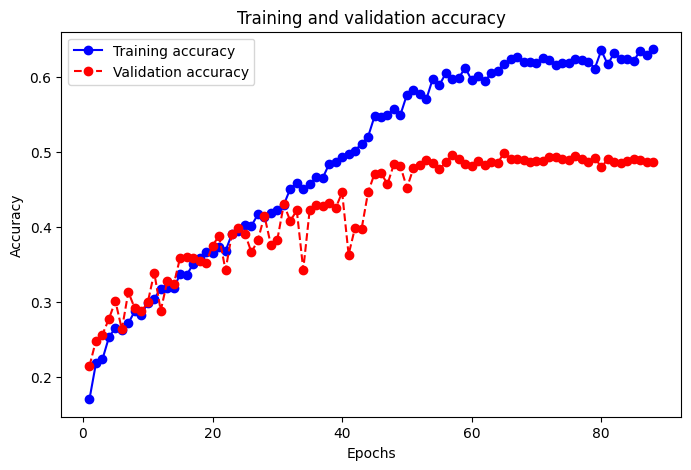

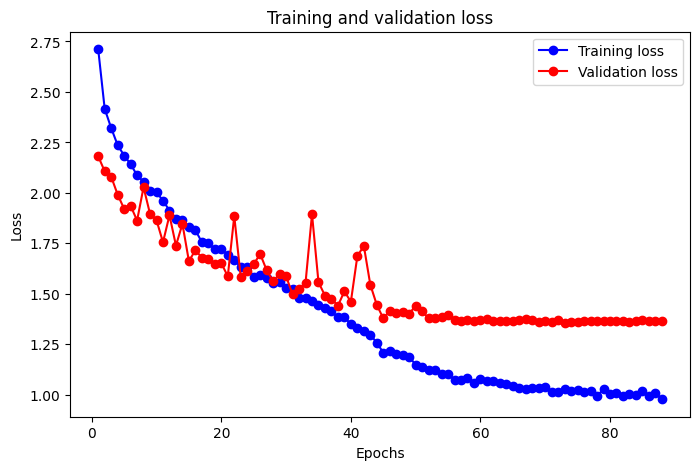

In [41]:
# Plot Experiment 2 learning curves
plot(history_exp2)

In [42]:
classifier_exp2.save("experiments/finetune_e3_e4_classifier.keras")

## Experiment 3: Full Fine-tuning (All Encoder Blocks)

In [43]:
# Experiment 3: Unfreeze entire encoder (full fine-tuning)
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

classifier_exp3, fexp3 = build_classifier_with_trainable_encoder(
    autoencoder, 
    trainable_layers=['e1', 'e2', 'e3', 'e4'],
    name_suffix='full_encoder'
)

trainable, non_trainable = count_trainable_params(classifier_exp3)
print(f"\nTrainable params: {trainable:,} ({trainable/1e6:.2f}M)")
print(f"Non-trainable params: {non_trainable:,} ({non_trainable/1e6:.2f}M)")
print(f"Trainable layers: e1, e2, e3, e4 (all encoder blocks)")

# Use lower learning rate for full fine-tuning
classifier_exp3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_exp3.summary()


Trainable params: 489,162 (0.49M)
Non-trainable params: 768 (0.00M)
Trainable layers: e1, e2, e3, e4 (all encoder blocks)


Model: "finetune_full_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_9 (Functional)       │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_7      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 489,162 (1.87 MB)

 Non-trainable params: 768 (3.00 KB)

In [44]:
# Train Experiment 3
reduce_lr_exp3 = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-7,
    verbose=1
)

early_stop_exp3 = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training Experiment 3: Full encoder fine-tuning...")
history_exp3 = classifier_exp3.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp3, early_stop_exp3],
    verbose=1
)

print(f"Best val accuracy: {max(history_exp3.history['val_accuracy']):.4f}")

print(f"Total epochs trained: {len(history_exp3.history['loss'])}")

Training Experiment 3: Full encoder fine-tuning...
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.1587 - loss: 2.8073 - val_accuracy: 0.1810 - val_loss: 2.1825 - learning_rate: 5.0000e-05
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.1945 - loss: 2.5046 - val_accuracy: 0.2170 - val_loss: 2.0835 - learning_rate: 5.0000e-05
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2200 - loss: 2.4018 - val_accuracy: 0.2340 - val_loss: 2.0711 - learning_rate: 5.0000e-05
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2330 - loss: 2.3217 - val_accuracy: 0.3060 - val_loss: 1.9545 - learning_rate: 5.0000e-05
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2410 - loss: 2.2593 - val_accuracy: 0.2940 - val_loss: 1.8997 - learning_rate: 5.0000e-05
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.2338 - loss: 2.2531 - val_accuracy: 0.2980 - val_loss: 1.9169 - learning_rate: 5.0000e-05
E

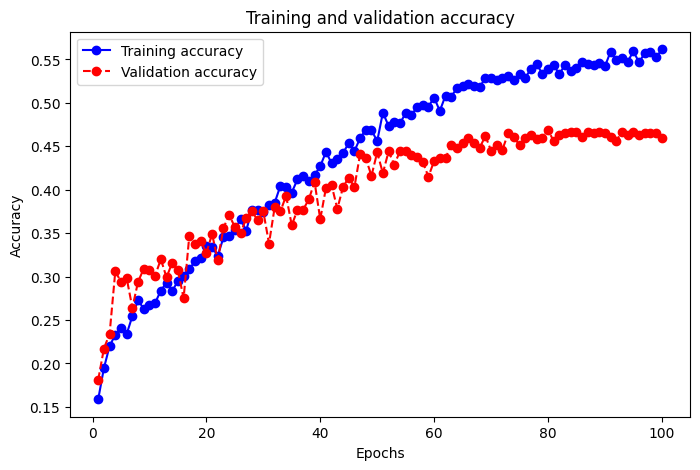

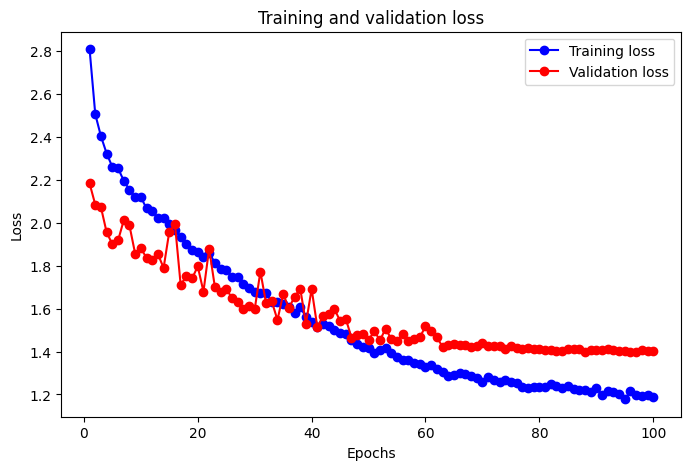

In [45]:
# Plot Experiment 3 learning curves
plot(history_exp3)

In [46]:
classifier_exp3.save("experiments/finetune_full_encoder_classifier.keras")

## Experiment 4: Warm-up Phase then Fine-tune e3 + e4

In [47]:
# Reload autoencoder to ensure clean state
autoencoder_exp4 = keras.models.load_model("experiments/basic_autoencoder.keras")

# Phase 1: Build classifier with FROZEN e3 and e4 (train dense layers only)
encoder_input = autoencoder_exp4.input
e4_output = autoencoder_exp4.get_layer('e4').output
feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)

# Freeze e3 and e4 during warm-up
for layer in feature_extractor.layers:
    layer.trainable = False

inputs = layers.Input(shape=(96, 96, 3))
x = feature_extractor(inputs)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier_exp4_phase1 = models.Model(inputs=inputs, outputs=outputs, name="finetune_e3_e4_warmup")

trainable, non_trainable = count_trainable_params(classifier_exp4_phase1)
print(f"\nPhase 1 - Warm-up:")
print(f"  Trainable params: {trainable/1e6:.2f}M")
print(f"  Non-trainable params: {non_trainable/1e6:.2f}M")

classifier_exp4_phase1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("\nPhase 1: Training dense layers with frozen encoder (warm-up)...")
history_exp4_p1 = classifier_exp4_phase1.fit(
    ds_train,
    validation_data=ds_val,
    epochs=10,
    callbacks=[],
    verbose=1
)

print(f"\nPhase 1 Results - Best val accuracy: {max(history_exp4_p1.history['val_accuracy']):.4f}")


Phase 1 - Warm-up:
  Trainable params: 0.10M
  Non-trainable params: 0.39M

Phase 1: Training dense layers with frozen encoder (warm-up)...
Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.1530 - loss: 2.8908 - val_accuracy: 0.1940 - val_loss: 2.1953
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2185 - loss: 2.4745 - val_accuracy: 0.2610 - val_loss: 1.9976
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2342 - loss: 2.4129 - val_accuracy: 0.2880 - val_loss: 1.9392
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2380 - loss: 2.3002 - val_accuracy: 0.2840 - val_loss: 1.9229
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2500 - loss: 2.2285 - val_accuracy: 0.2920 - val_loss: 1.9024
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2625 - loss: 2.1962 - val_accuracy: 0.3100 - val_loss: 1.8848
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.2620 - loss: 2.1834 - val

In [48]:
# Unfreeze e3 and e4 in the same model
for layer in classifier_exp4_phase1.layers:
    if layer.name in ['e3', 'e4']:
        layer.trainable = True

# Verify trainable params increased
trainable, non_trainable = count_trainable_params(classifier_exp4_phase1)
print(f"\nPhase 2 - Fine-tuning:")
print(f"  Trainable params: {trainable/1e6:.2f}M")
print(f"  Non-trainable params: {non_trainable/1e6:.2f}M")
print(f"  Trainable layers: All (dense + e3,e4)")

# Compile with lower learning rate for fine-tuning
classifier_exp4_phase1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

reduce_lr_exp4_p2 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-7,
    verbose=1
)

early_stop_exp4_p2 = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history_exp4_p2 = classifier_exp4_phase1.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp4_p2, early_stop_exp4_p2],
    verbose=1
)

print(f"Phase 2 (fine-tune) best val accuracy: {max(history_exp4_p2.history['val_accuracy']):.4f}")

print(f"Total epochs trained: {len(history_exp4_p1.history['loss']) + len(history_exp4_p2.history['loss'])}")


Phase 2 - Fine-tuning:
  Trainable params: 0.10M
  Non-trainable params: 0.39M
  Trainable layers: All (dense + e3,e4)
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.2580 - loss: 2.1444 - val_accuracy: 0.2280 - val_loss: 2.4159 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2695 - loss: 2.0213 - val_accuracy: 0.2910 - val_loss: 1.9542 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2910 - loss: 1.9406 - val_accuracy: 0.2860 - val_loss: 1.8381 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.3002 - loss: 1.8839 - val_accuracy: 0.2900 - val_loss: 1.9717 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3072 - loss: 1.8300 - val_accuracy: 0.3370 - val_loss: 1.7639 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3275 - loss: 1.8054 - val_accuracy: 0.2930 - val

In [49]:
# Save the best model from Experiment 4
classifier_exp4_phase1.save("experiments/finetune_warmup_e3_e4.keras")
print("Experiment 4 model saved: experiments/finetune_warmup_e3_e4.keras")

Experiment 4 model saved: experiments/finetune_warmup_e3_e4.keras


## Evaluation E1 + E2 + E3 + E4

In [50]:
print("\n" + "="*60)
print("Validation Comparison")
print("="*60)
print(f"Frozen encoder (baseline) - Val Acc: {max(history_e6.history['val_accuracy']):.4f} | Val Loss: {min(history_e6.history['val_loss']):.4f}")
print(f"Fine-tune e4 only - Val Acc: {max(history_exp1.history['val_accuracy']):.4f} | Val Loss: {min(history_exp1.history['val_loss']):.4f}")
print(f"Fine-tune e3 + e4 - Val Acc: {max(history_exp2.history['val_accuracy']):.4f} | Val Loss: {min(history_exp2.history['val_loss']):.4f}")
print(f"Full encoder fine-tune - Val Acc: {max(history_exp3.history['val_accuracy']):.4f} | Val Loss: {min(history_exp3.history['val_loss']):.4f}")
print(f"Warm-up + fine-tune e3,e4 - Val Acc: {max(history_exp4_p2.history['val_accuracy']):.4f} | Val Loss: {min(history_exp4_p2.history['val_loss']):.4f}")

print("\n" + "="*60)
print("Test Set Evaluation")
print("="*60)
classifier_baseline = keras.models.load_model("experiments/e6_classifier.keras")
classifier_exp1 = keras.models.load_model("experiments/finetune_e4_only.keras")
classifier_exp2 = keras.models.load_model("experiments/finetune_e3_e4_classifier.keras")
classifier_exp3 = keras.models.load_model("experiments/finetune_full_encoder_classifier.keras")
classifier_exp4 = keras.models.load_model("experiments/finetune_warmup_e3_e4.keras")

for name, model in [
    ('Baseline', classifier_baseline),
    ('Exp1: e4 only', classifier_exp1),
    ('Exp2: e3+e4', classifier_exp2),
    ('Exp3: Full encoder', classifier_exp3),
    ('Exp4: Warm-up + fine-tune', classifier_exp4)
]:
    test_loss, test_acc = model.evaluate(ds_test, verbose=0)
    print(f"{name}: Test accuracy = {test_acc:.4f} | Test loss = {test_loss:.4f}")



Validation Comparison
Frozen encoder (baseline) - Val Acc: 0.4190 | Val Loss: 1.7203
Fine-tune e4 only - Val Acc: 0.4430 | Val Loss: 1.5245
Fine-tune e3 + e4 - Val Acc: 0.4990 | Val Loss: 1.3576
Full encoder fine-tune - Val Acc: 0.4690 | Val Loss: 1.3970
Warm-up + fine-tune e3,e4 - Val Acc: 0.4300 | Val Loss: 1.5407

Test Set Evaluation
Baseline: Test accuracy = 0.4374 | Test loss = 1.6803
Exp1: e4 only: Test accuracy = 0.4489 | Test loss = 1.4829
Exp2: e3+e4: Test accuracy = 0.5051 | Test loss = 1.3423
Exp3: Full encoder: Test accuracy = 0.4952 | Test loss = 1.3690
Exp4: Warm-up + fine-tune: Test accuracy = 0.4351 | Test loss = 1.5164


## Experiment 5: Regularization + Partial Fine-tuning (Last 2 Blocks - e3 + e4)

In [ ]:
def build_classifier_with_trainable_encoder_regularized(autoencoder, trainable_layers, name_suffix):
    encoder_input = autoencoder.input
    e4_output = autoencoder.get_layer('e4').output
    feature_extractor = models.Model(inputs=encoder_input, outputs=e4_output)
    
    for layer in feature_extractor.layers:
        layer.trainable = layer.name in trainable_layers
    
    inputs = layers.Input(shape=(96, 96, 3))
    x = feature_extractor(inputs)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l1(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l1(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(10, activation='softmax')(x)
    classifier = models.Model(inputs=inputs, outputs=outputs, name=f"finetune_{name_suffix}")
    
    return classifier, feature_extractor

In [62]:
# Experiment 5: Regularized and Unfreeze last 2 encoder blocks (e3 + e4)
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")

classifier_exp5, fexp5 = build_classifier_with_trainable_encoder_regularized(
    autoencoder, 
    trainable_layers=['e3', 'e4'],
    name_suffix='e3_e4'
)

trainable, non_trainable = count_trainable_params(classifier_exp5  )
print(f"\nTrainable params: {trainable:,} ({trainable/1e6:.2f}M)")
print(f"Non-trainable params: {non_trainable:,} ({non_trainable/1e6:.2f}M)")
print(f"Trainable layers: e3, e4 (last 2 encoder blocks)")

classifier_exp5.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier_exp5.summary()


Trainable params: 469,770 (0.47M)
Non-trainable params: 20,160 (0.02M)
Trainable layers: e3, e4 (last 2 encoder blocks)


Model: "finetune_e3_e4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ functional_15 (Functional)      │ (None, 6, 6, 256)      │       388,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,930 (1.87 MB)

 Trainable params: 469,770 (1.79 MB)

 Non-trainable params: 20,160 (78.75 KB)

In [63]:
# Train Experiment 5
reduce_lr_exp5 = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.5, 
    patience=5, 
    min_lr=1e-6,
    verbose=1
)

early_stop_exp5 = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

print("Training Experiment 5: Regularization + Partial Fine-tuning (Last 2 Blocks - e3 + e4)...")
history_exp5 = classifier_exp5.fit(
    ds_train,
    validation_data=ds_val,
    epochs=100,
    callbacks=[reduce_lr_exp5, early_stop_exp5],
    verbose=1
)

print(f"Best val accuracy: {max(history_exp5.history['val_accuracy']):.4f}")

print(f"Total epochs trained: {len(history_exp5.history['loss'])}")

Training Experiment 5: Regularization + Partial Fine-tuning (Last 2 Blocks - e3 + e4)...
Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.2440 - loss: 2.7092 - val_accuracy: 0.2060 - val_loss: 2.8925 - learning_rate: 1.0000e-04
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3043 - loss: 2.4089 - val_accuracy: 0.2580 - val_loss: 2.7144 - learning_rate: 1.0000e-04
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3332 - loss: 2.2817 - val_accuracy: 0.3070 - val_loss: 2.4072 - learning_rate: 1.0000e-04
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3618 - loss: 2.1825 - val_accuracy: 0.3260 - val_loss: 2.3620 - learning_rate: 1.0000e-04
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3855 - loss: 2.1113 - val_accuracy: 0.3270 - val_loss: 2.3910 - learning_rate: 1.0000e-04
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.4145 - loss: 2.0343 - val_accuracy: 0.3180 - val_loss

In [64]:
print("\n--- Test Evaluation ---")
test_loss_exp5, test_acc_exp5 = classifier_exp5.evaluate(ds_test)
print(f"Test Accuracy: {test_acc_exp5:.4f} | Test Loss: {test_loss_exp5:.4f}")


--- Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4410 - loss: 1.9559
Test Accuracy: 0.4410 | Test Loss: 1.9559
